# Kaggle classification — ET Hybrid + CatBoost + LightGBM stacking

**Goal:** train an Extra Trees hybrid (global Extra Trees + subject-specific Random Forest), CatBoost, and LightGBM as **base learners**, and use Logistic Regression as the **meta-learner**. Produce a Kaggle-ready `id,output` submission.

**Important:** The *exact* implementation of the previously successful “ET hybrid + within-subject RF ranking for E/J (eps=0.01)” was not supplied here. This notebook uses an **explicit, reproducible approximation**: Extra Trees predictions blended with a subject-specific Random Forest when there are enough observations. It **does not claim to reproduce your prior 0.77 score**. Optional E/J ranking is included as a separate experiment and is **disabled by default**. Only apply it if that matches your competition's allowed features and helps your validation metric.

**Evaluation:** default ROC-AUC; update `PRIMARY_METRIC` if your competition scores something else. All stacking meta-features are obtained **out-of-fold**, avoiding training the meta-learner on in-sample base predictions.

## 1. Install dependencies (once, if necessary)

In [1]:
# Uncomment if your environment is missing these packages, then restart the kernel.
# %pip install -U numpy pandas scikit-learn catboost lightgbm matplotlib joblib

## 2. Imports and configuration

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, StackingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, log_loss, RocCurveDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
import joblib

SEED = 42
PRIMARY_METRIC = "roc_auc"  # Change if Kaggle competition uses a different metric.
VAL_SIZE = 0.20
N_FOLDS = 3  # 3 first for speed; try 5 for final experiments
OUTPUT_DIR = Path(".")
np.random.seed(SEED)

## 3. Load train, test, and submission template

In [3]:
def first_existing(name):
    locations = [Path("./src") / name, Path(".") / name]
    for path in locations:
        if path.exists():
            return path
    raise FileNotFoundError(f"Could not find {name}; checked: {locations}")

train = pd.read_csv(first_existing("train_data.csv"))
test = pd.read_csv(first_existing("test_data.csv"))
sample_solution = pd.read_csv(first_existing("sample_solution.csv"))

assert "output" in train.columns, "Training labels must be in 'output'."
assert "output" in sample_solution.columns, "Submission template must contain 'output'."
assert len(test) == len(sample_solution), "Test and submission template row counts differ."
print("Train:", train.shape, "Test:", test.shape, "Template:", sample_solution.shape)
print("Class distribution:", train["output"].value_counts(normalize=True))
display(train.head(2))

Train: (4584, 670) Test: (1732, 669) Template: (1732, 2)
Class distribution: output
1    0.844895
0    0.155105
Name: proportion, dtype: float64


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,z217,z218,z219,z220,z221,z222,subject,phase,state,output
0,0,0,0,1,-323.106605,2.694366,-1.987520,261.092784,0.013704,0.000100,...,-0.004930,-0.005554,5.246375,-7.534092,3.530736,-0.539045,K,3,C,1
1,0,0,0,1,-376.084691,0.969696,-6.933765,355.311648,0.030292,-0.000153,...,0.022757,0.052506,-3.727741,-2.854443,-0.699268,-0.054074,A,4,C,1


## 4. Prepare features without fitting preprocessing on validation data

In [4]:
target_col = "output"
# Never train on an id column if it is present only as a row identifier.
excluded_cols = [target_col, "id"]
feature_cols = [c for c in train.columns if c not in excluded_cols]
missing_test_cols = set(feature_cols) - set(test.columns)
if missing_test_cols:
    raise ValueError(f"Missing test features: {sorted(missing_test_cols)[:10]}")
X = train[feature_cols].copy()
y = train[target_col].astype(int)
X_test = test.reindex(columns=feature_cols).copy()
assert sorted(y.unique().tolist()) == [0, 1], "This notebook expects labels 0 and 1."
print("Features:", len(feature_cols), "Subject feature present:", "subject" in X.columns)

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in feature_cols if c not in numeric_cols]
print("Numerical:", len(numeric_cols), "Categorical:", cat_cols)

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median", add_indicator=False), numeric_cols),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]), cat_cols),
        ],
        remainder="drop",
        sparse_threshold=0.0
    )

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=VAL_SIZE, random_state=SEED, stratify=y
)
print("Training:", X_train.shape, "Validation:", X_val.shape)

Features: 669 Subject feature present: True
Numerical: 667 Categorical: ['subject', 'state']
Training: (3667, 669) Validation: (917, 669)


## 5. ET Hybrid classifier: global Extra Trees + per-subject Random Forest

For subject groups with enough labeled examples **containing both classes**, train a small Random Forest using **only that subject's training rows**. At inference, mix its class-1 probability with the global Extra Trees probability. Unseen/small/one-class subjects use global Extra Trees alone. The optional `subject` column is used to **route** predictions; do not include `output` or any test labels.

This is a self-contained model that can be cloned by `StackingClassifier` inside its cross-validation folds.

In [5]:
class ETHybridClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=300, rf_estimators=120,
                 local_weight=0.30, min_subject_rows=40,
                 max_features=0.7, min_samples_leaf=2, random_state=42,
                 n_jobs=2):
        self.n_estimators = n_estimators
        self.rf_estimators = rf_estimators
        self.local_weight = local_weight
        self.min_subject_rows = min_subject_rows
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=feature_cols)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        if not np.array_equal(self.classes_, [0, 1]):
            raise ValueError("Training fold must contain classes 0 and 1.")
        self.preprocessor_ = make_preprocessor()
        Xt = self.preprocessor_.fit_transform(X)
        self.global_model_ = ExtraTreesClassifier(
            n_estimators=self.n_estimators,
            max_features=self.max_features,
            min_samples_leaf=self.min_samples_leaf,
            class_weight="balanced",
            random_state=self.random_state,
            n_jobs=self.n_jobs
        ).fit(Xt, y)
        self.local_models_ = {}
        if "subject" in X.columns:
            subjects = X["subject"].astype("string").fillna("__MISSING__").to_numpy()
            for subject in np.unique(subjects):
                idx = np.flatnonzero(subjects == subject)
                if len(idx) < self.min_subject_rows or len(np.unique(y[idx])) != 2:
                    continue
                rf = RandomForestClassifier(
                    n_estimators=self.rf_estimators,
                    min_samples_leaf=self.min_samples_leaf,
                    class_weight="balanced_subsample",
                    random_state=self.random_state,
                    n_jobs=self.n_jobs
                )
                rf.fit(Xt[idx], y[idx])
                self.local_models_[subject] = rf
        return self

    def predict_proba(self, X):
        X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=feature_cols)
        Xt = self.preprocessor_.transform(X)
        p = self.global_model_.predict_proba(Xt)[:, 1]
        if "subject" in X.columns and self.local_models_:
            subjects = X["subject"].astype("string").fillna("__MISSING__").to_numpy()
            for subject, rf in self.local_models_.items():
                idx = np.flatnonzero(subjects == subject)
                if len(idx):
                    p[idx] = ((1 - self.local_weight) * p[idx]
                              + self.local_weight * rf.predict_proba(Xt[idx])[:, 1])
        return np.column_stack([1.0 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

## 6. Build base models and the logistic regression stacking meta-learner

In [6]:
def make_base_estimators():
    et_hybrid = ETHybridClassifier(
        n_estimators=300, rf_estimators=120,
        local_weight=0.30, min_subject_rows=40,
        random_state=SEED, n_jobs=2
    )
    cat_model = Pipeline([
        ("prep", make_preprocessor()),
        ("model", CatBoostClassifier(
            iterations=400, depth=5, learning_rate=0.035,
            loss_function="Logloss", verbose=False,
            random_seed=SEED, thread_count=2,
            l2_leaf_reg=4
        ))
    ])
    lgb_model = Pipeline([
        ("prep", make_preprocessor()),
        ("model", LGBMClassifier(
            n_estimators=350, learning_rate=0.035,
            num_leaves=15, max_depth=-1,
            min_child_samples=25,
            colsample_bytree=0.8, subsample=0.8,
            reg_lambda=2.0,
            random_state=SEED, n_jobs=2,
            verbosity=-1
        ))
    ])
    return [("et_hybrid", et_hybrid), ("catboost", cat_model), ("lightgbm", lgb_model)]

def make_stacking_model():
    return StackingClassifier(
        estimators=make_base_estimators(),
        final_estimator=LogisticRegression(C=0.5, max_iter=2000),
        stack_method="predict_proba",
        cv=StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED),
        passthrough=False,
        n_jobs=1  # avoid nested joblib parallelization + excessive memory usage
    )

stack = make_stacking_model()
print(stack)

StackingClassifier(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimators=[('et_hybrid', ETHybridClassifier()),
                               ('catboost',
                                Pipeline(steps=[('prep',
                                                 ColumnTransformer(sparse_threshold=0.0,
                                                                   transformers=[('num',
                                                                                  SimpleImputer(strategy='median'),
                                                                                  ['x1',
                                                                                   'x2',
                                                                                   'x3',
                                                                                   'x4',
                                                                                   'x5',
          

## 7. Fit on training subset and evaluate on untouched validation holdout

,model,roc_auc,pr_auc,accuracy_at_0.5,log_loss
1,et_hybrid,0.89800,0.97919,0.87568,0.28135
0,ET Hybrid + CatBoost + LightGBM stack,0.89701,0.97920,0.87568,0.29025
2,catboost,0.87845,0.97470,0.86914,0.29990
3,lightgbm,0.86624,0.97203,0.85932,0.30691


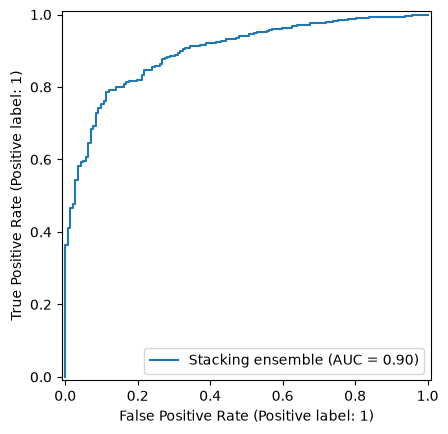

In [7]:
stack.fit(X_train, y_train)
val_stack_p = stack.predict_proba(X_val)[:, 1]
results = []

def evaluate_model(label, p):
    p = np.asarray(p)
    scores = {
        "model": label,
        "roc_auc": roc_auc_score(y_val, p),
        "pr_auc": average_precision_score(y_val, p),
        "accuracy_at_0.5": accuracy_score(y_val, (p >= 0.5).astype(int)),
        "log_loss": log_loss(y_val, p, labels=[0, 1])
    }
    results.append(scores)
    return scores

evaluate_model("ET Hybrid + CatBoost + LightGBM stack", val_stack_p)
# These are base learners fitted on X_train after the meta-learner OOF phase.
val_base_probs = {}
for name, fitted_est in stack.named_estimators_.items():
    val_base_probs[name] = fitted_est.predict_proba(X_val)[:, 1]
    evaluate_model(name, val_base_probs[name])

performance = pd.DataFrame(results).sort_values(PRIMARY_METRIC, ascending=False)
display(performance.round(5))
RocCurveDisplay.from_predictions(y_val, val_stack_p, name="Stacking ensemble")
plt.show()

## 8. Optional baseline: fixed weighted blending

This is a *comparison*, not stacking. The weights are illustrative and **should not be optimized on the public leaderboard**. Change them using cross-validated/holdout measurements.

In [9]:
blend_p = (0.60 * val_base_probs["et_hybrid"]
           + 0.25 * val_base_probs["catboost"]
           + 0.15 * val_base_probs["lightgbm"])
print(evaluate_model("Weighted blend 60/25/15", blend_p))
display(pd.DataFrame(results).sort_values(PRIMARY_METRIC, ascending=False).round(5))

{'model': 'Weighted blend 60/25/15', 'roc_auc': 0.8959018627896411, 'pr_auc': 0.9790194664858882, 'accuracy_at_0.5': 0.871319520174482, 'log_loss': 0.28310629127319165}


,model,roc_auc,pr_auc,accuracy_at_0.5,log_loss
1,et_hybrid,0.89800,0.97919,0.87568,0.28135
0,ET Hybrid + CatBoost + LightGBM stack,0.89701,0.97920,0.87568,0.29025
5,Weighted blend 60/25/15,0.89590,0.97902,0.87132,0.28311
4,Weighted blend 50/35/15,0.89500,0.97892,0.87241,0.28460
2,catboost,0.87845,0.97470,0.86914,0.29990
3,lightgbm,0.86624,0.97203,0.85932,0.30691


## 9. Optional E/J within-subject ranking — OFF by default

Your prior strategy used *within-subject RF ranking for E/J (eps=0.01)*. The exact original method is unavailable. The **illustrative** transform below ranks the **ensemble probabilities** within each `subject` where `phase` equals `E` or `J`. This is not equivalent to ranking with a trained RF. It can harm ROC-AUC, and changing prediction probabilities also affects log loss. Keep it disabled unless your experiment shows a benefit and it is permitted by the competition.

If your `phase` field is numeric instead of `E`/`J`, this transform leaves values unchanged.

In [10]:
USE_APPROX_EJ_RANKING = False
RANK_EPS = 0.01

def approximate_ej_ranking(probs, feature_frame, eps=0.01):
    probs = np.asarray(probs, dtype=float).copy()
    if not {"subject", "phase"}.issubset(feature_frame.columns):
        return probs
    frame = pd.DataFrame({
        "subject": feature_frame["subject"].astype("string").to_numpy(),
        "phase": feature_frame["phase"].astype("string").str.upper().to_numpy(),
        "prob": probs
    })
    eligible = frame["phase"].isin(["E", "J"])
    if not eligible.any():
        return probs
    for _, inds in frame[eligible].groupby("subject", dropna=False).groups.items():
        idx = np.asarray(list(inds), dtype=int)
        if len(idx) < 2:
            continue
        ranks = pd.Series(probs[idx]).rank(pct=True).to_numpy()
        probs[idx] = np.clip((1.0 - eps) * ranks + eps * probs[idx], 0, 1)
    return probs

if USE_APPROX_EJ_RANKING:
    ranked_val_p = approximate_ej_ranking(val_stack_p, X_val.reset_index(drop=True), RANK_EPS)
    print(evaluate_model("Stack + approximate E/J ranking", ranked_val_p))
else:
    print("Approximate E/J ranking is disabled.")

Approximate E/J ranking is disabled.


## 10. Select model by validation metric, refit on **all training rows**, save Kaggle file

By default the **stack** is selected, even if the illustrative weighted blend scores better; you can switch `FINAL_METHOD` after checking your holdout results. The ranking toggle is independent. This final fit **does not** use test labels.

In [11]:
FINAL_METHOD = "stack"  # "stack" or "blend"

if FINAL_METHOD == "stack":
    final_model = make_stacking_model()
    final_model.fit(X, y)
    test_probs = final_model.predict_proba(X_test)[:, 1]
elif FINAL_METHOD == "blend":
    final_models = {}
    for name, model in make_base_estimators():
        fitted = clone(model).fit(X, y)
        final_models[name] = fitted
    test_probs = (0.60 * final_models["et_hybrid"].predict_proba(X_test)[:, 1]
                  + 0.25 * final_models["catboost"].predict_proba(X_test)[:, 1]
                  + 0.15 * final_models["lightgbm"].predict_proba(X_test)[:, 1])
else:
    raise ValueError("FINAL_METHOD must be 'stack' or 'blend'.")

if USE_APPROX_EJ_RANKING:
    test_probs = approximate_ej_ranking(test_probs, X_test.reset_index(drop=True), RANK_EPS)

assert len(test_probs) == len(test)
assert np.isfinite(test_probs).all()
assert ((test_probs >= 0) & (test_probs <= 1)).all()

submission = sample_solution.copy()
submission["output"] = test_probs
# Retain the ids and column order exactly as provided by sample_solution.csv
submission_path = OUTPUT_DIR / "et_hybrid_catboost_lightgbm_stacking_submission.csv"
submission.to_csv(submission_path, index=False)
print("Saved:", submission_path.resolve())
print("Shape:", submission.shape)
display(submission.head())

Saved: /Users/nilavaghosh/Desktop/E82Advanced ML/Homeworks/HW3/ml_classifier_experiments/et_hybrid_catboost_lightgbm_stacking_submission.csv
Shape: (1732, 2)


,id,output
0,0,0.895311
1,1,0.946469
2,2,0.874373
3,3,0.818664
4,4,0.889126


## 11. Save local validation results and final fitted model

In [12]:
pd.DataFrame(results).sort_values(PRIMARY_METRIC, ascending=False).to_csv(
    OUTPUT_DIR / "stacking_validation_metrics.csv", index=False
)
model_file = OUTPUT_DIR / "et_hybrid_stack_model.joblib"
joblib.dump(final_model if FINAL_METHOD == "stack" else final_models, model_file)
print("Saved metrics and fitted model.")
print("Kaggle upload file:", submission_path.name)
# Optional CLI submission (update your actual competition slug):
# !kaggle competitions submit -c YOUR_COMPETITION_SLUG -f et_hybrid_catboost_lightgbm_stacking_submission.csv -m "ET hybrid CatBoost LightGBM stack"

Saved metrics and fitted model.
Kaggle upload file: et_hybrid_catboost_lightgbm_stacking_submission.csv


## Notes on reliability and next experiments

- **No leakage in stacking:** `StackingClassifier` makes out-of-fold predictions for the meta-learner; preprocessing and subject-specific RF are fitted independently inside each base learner/fold.
- **Validate the metric:** A leaderboard score of 0.77 is not necessarily ROC-AUC. Confirm the Kaggle competition's scoring definition before choosing models or ranking operations.
- **Subject split:** The default `StratifiedKFold` assumes observations may share subjects across folds. If Kaggle holds out entirely unseen subjects, use a `GroupKFold`-style strategy for validation and for stacking; this notebook does not claim subject-generalization scores.
- **Computation:** A 3-fold stack refits each base model several times. The configuration limits nested parallelism for an Apple M2 / 16 GB setup; reduce tree counts if runtime or memory is too high.
- **Original 0.77 hybrid:** If you can provide its code, replace `ETHybridClassifier` with the precise original estimator; do not assume this approximation matches it.
- **No public leaderboard tuning:** Choose hyperparameters with honest local validation and limit leaderboard submissions.
